# ML Assignment 2 – Multi-class Classification (5 models)

## Student Details:
Name : Saswata Bandyopadhyay  
Bits ID: 2026CT05022  
Email : 2026ct05022@wilp.bits-pilani.ac.in 

**Dataset:** Optical Recognition of Handwritten Digits (UCI), loaded through `sklearn.datasets.load_digits` – 1,797 rows, 64 numeric features, 10 classes.  
**Models:** 
  *  Logistic Regression
  *  Decision Tree
  *  kNN
  *  Gaussian Naive Bayes
  *  Random Forest


**Metrics:** Accuracy, AUC, Precision, Recall, F1, MCC (macro-averaged for the multi-class case).

In [1]:
import os, time, joblib, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42
TARGET = "target"

# Resolve the repository layout without creating directories.
cwd = Path.cwd().resolve()
if (cwd / "model").is_dir() and (cwd / "images").is_dir():
    PROJECT_ROOT = cwd
elif cwd.name.lower() == "model" and (cwd.parent / "model").is_dir() and (cwd.parent / "images").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

MODEL_DIR = PROJECT_ROOT / "model"
IMAGE_DIR = PROJECT_ROOT / "images"
TEST_DATA_PATH = PROJECT_ROOT / "test_data.csv"
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\desum\Desktop\All Doc\Saswata\bits\New folder\2026ct05022-ML-Assignment2


## Step 1 – Dataset choice and exploration
**Source:** UCI Machine Learning Repository, *Optical Recognition of Handwritten Digits* (https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits). scikit-learn bundles the 1,797-sample test portion of that dataset (the full UCI file has 5,620 samples), so that subset is what is used here.

**Why this dataset:** it satisfies the brief (64 features ≥ 12, 1,797 rows ≥ 1,000), it is a genuine **multi-class** problem (10 digits), which makes the choice of macro-averaged metrics and one-vs-rest AUC worth discussing, and its 64 pixel features let scale-sensitive models (Logistic Regression, kNN) be compared with tree-based and probabilistic ones.

**Target variable:** `target` – the digit (0–9) shown in the image.
**Features:** 64 numeric columns `pixel_r_c` – the intensity (integer 0–16) of each pixel of an 8×8 image (stored as float64). There are no categorical features.

In [2]:
raw = load_digits(as_frame=True).frame
X_all = raw.drop(columns=TARGET)
print("Shape:", raw.shape, "| target column:", TARGET)
print("Feature dtypes:", X_all.dtypes.unique().tolist())
print("Pixel value range: %d to %d | all values integer-valued: %s" %
      (X_all.values.min(), X_all.values.max(), bool((X_all.values == X_all.values.round()).all())))
const_cols = X_all.columns[X_all.nunique() == 1].tolist()
print("Constant (always-zero) pixel columns:", const_cols)
raw.head()

Shape: (1797, 65) | target column: target
Feature dtypes: [dtype('float64')]
Pixel value range: 0 to 16 | all values integer-valued: True
Constant (always-zero) pixel columns: ['pixel_0_0', 'pixel_4_0', 'pixel_4_7']


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


target
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Imbalance ratio (max/min): 1.05


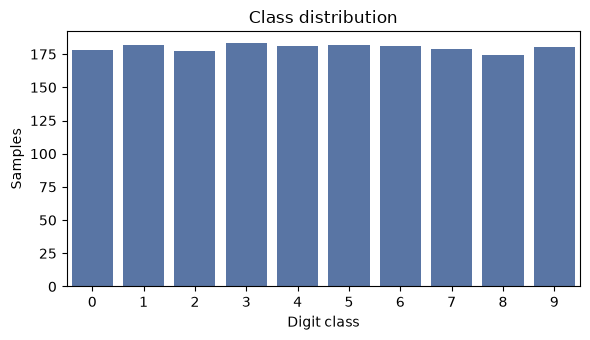

In [3]:
counts = raw[TARGET].value_counts().sort_index()
print(counts.to_string())
print("Imbalance ratio (max/min): %.2f" % (counts.max() / counts.min()))
plt.figure(figsize=(6, 3.5))
sns.barplot(x=counts.index, y=counts.values, color="#4C72B0")
plt.xlabel("Digit class"); plt.ylabel("Samples"); plt.title("Class distribution")
plt.tight_layout(); plt.savefig(IMAGE_DIR / "class_distribution.png", dpi=150); plt.show()

**Class distribution:** the ten classes are almost perfectly balanced (174–183 samples each, max/min ratio ≈ 1.05), so there is no class-imbalance problem and no resampling or class weights are needed.

## Step 2 – Preprocessing
* **Missing values / duplicates:** checked below – none in this dataset (so the imputer and the de-duplication step are safeguards, not real changes).
* **Encoding:** no categorical features; the target is already integer-coded.
* **Scaling:** `StandardScaler` (needed by Logistic Regression and kNN; harmless for the others). Three pixel columns are always 0; the scaler leaves them at 0.
* **Split:** stratified 80:20, `random_state=42`.
* **No leakage:** imputer and scaler are inside a `Pipeline`, so they are fitted on the training data only.

In [4]:
print("Missing cells:", int(raw.isna().sum().sum()), "| duplicate rows:", int(raw.duplicated().sum()))
data = raw.drop_duplicates().reset_index(drop=True)      # no-op here, kept so the pipeline is dataset-agnostic

X, y = data.drop(columns=TARGET), data[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_tr.shape, "Test:", X_te.shape)
print("Class share train vs test (max abs diff): %.4f" %
      (y_tr.value_counts(normalize=True).sort_index() - y_te.value_counts(normalize=True).sort_index()).abs().max())

pd.concat([X_te, y_te], axis=1).to_csv(TEST_DATA_PATH, index=False)   # test data for the repo

def make_pipe(est):
    # imputer and scaler live inside the pipeline, so they are fitted on training data only
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("clf", est)])

Missing cells: 0 | duplicate rows: 0
Train: (1437, 64) Test: (360, 64)
Class share train vs test (max abs diff): 0.0019


## Step 3 – Models and metrics
**Hyperparameters.** Logistic Regression, kNN (k=5) and Random Forest (200 trees) use sensible defaults. The two models whose defaults are known to be sensitive – Gaussian Naive Bayes (`var_smoothing`) and the Decision Tree (`max_depth`, `min_samples_leaf`) – are chosen by 5-fold cross-validation on the **training set only**; the test set plays no part in choosing them.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grids = {
    "Naive Bayes": (GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-2, 1e-1, 1]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
                      {"clf__max_depth": [5, 8, 12, None], "clf__min_samples_leaf": [1, 2, 5]}),
}
best_params = {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(make_pipe(est), grid, cv=cv, scoring="accuracy").fit(X_tr, y_tr)   # training data only
    best_params[name] = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    print("%-14s best params: %s | CV accuracy on train: %.4f" % (name, best_params[name], gs.best_score_))

Naive Bayes    best params: {'var_smoothing': 0.1} | CV accuracy on train: 0.9047
Decision Tree  best params: {'max_depth': None, 'min_samples_leaf': 1} | CV accuracy on train: 0.8414


In [6]:
candidates = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, random_state=SEED)),
    "Decision Tree": make_pipe(DecisionTreeClassifier(random_state=SEED, **best_params["Decision Tree"])),
    "kNN": make_pipe(KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": make_pipe(GaussianNB(**best_params["Naive Bayes"])),
    "Random Forest (Ensemble)": make_pipe(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
}
rows, extra, cms = [], [], {}
for name, pipe in candidates.items():
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = pipe.predict(X_te); pred_s = time.perf_counter() - t0
    proba = pipe.predict_proba(X_te)
    rows.append({"ML Model Name": name,
        "Accuracy":  accuracy_score(y_te, pred),
        "AUC":       roc_auc_score(y_te, proba, multi_class="ovr", average="macro"),
        "Precision": precision_score(y_te, pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_te, pred, average="macro", zero_division=0),
        "F1":        f1_score(y_te, pred, average="macro", zero_division=0),
        "MCC":       matthews_corrcoef(y_te, pred)})
    extra.append({"ML Model Name": name, "Train accuracy": pipe.score(X_tr, y_tr),
                  "Test errors": int((pred != y_te).sum()), "Fit time (s)": fit_s, "Predict time (s)": pred_s})
    cms[name] = confusion_matrix(y_te, pred)
    model_name = name.split(" (")[0].lower().replace(" ", "_")
    joblib.dump(pipe, MODEL_DIR / (model_name + ".joblib"))

results = pd.DataFrame(rows).set_index("ML Model Name").round(4)
extra_df = pd.DataFrame(extra).set_index("ML Model Name").round(4)
print("Precision, Recall, F1 and AUC are macro-averaged (AUC: one-vs-rest).")
display(results) if "display" in globals() else print(results)
extra_df

Precision, Recall, F1 and AUC are macro-averaged (AUC: one-vs-rest).
                          Accuracy     AUC  Precision  Recall      F1     MCC
ML Model Name                                                                
Logistic Regression         0.9722  0.9991     0.9721  0.9719  0.9719  0.9692
Decision Tree               0.8167  0.8978     0.8156  0.8159  0.8148  0.7965
kNN                         0.9639  0.9950     0.9646  0.9637  0.9634  0.9600
Naive Bayes                 0.8917  0.9798     0.8947  0.8908  0.8918  0.8798
Random Forest (Ensemble)    0.9639  0.9992     0.9644  0.9635  0.9634  0.9600


,Train accuracy,Test errors,Fit time (s),Predict time (s)
ML Model Name,,,,
Logistic Regression,0.9993,10,0.1092,0.0042
Decision Tree,1.0000,66,0.0273,0.0025
kNN,0.9840,13,0.0099,0.0775
Naive Bayes,0.9200,39,0.0143,0.0028
Random Forest (Ensemble),1.0000,13,0.4283,0.0533


## Visualisation of all metrics

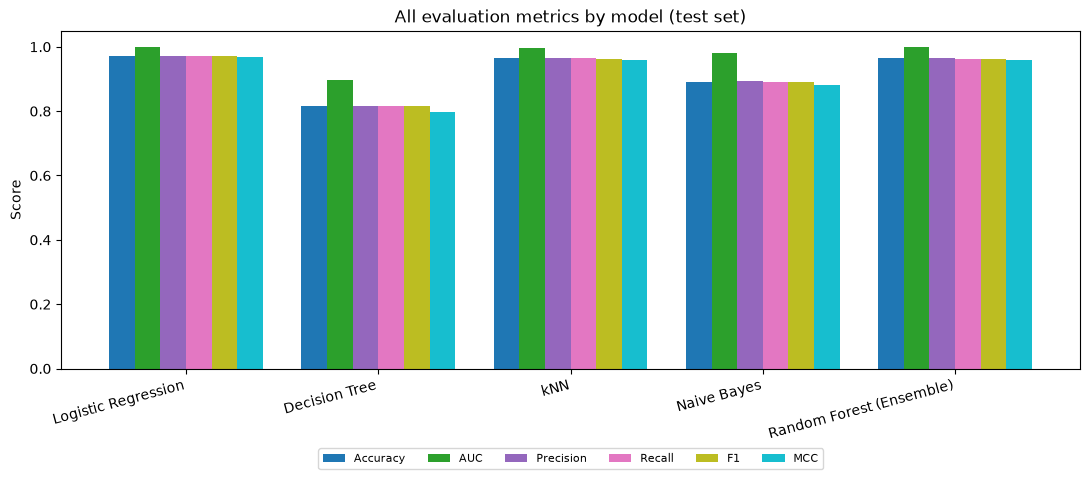

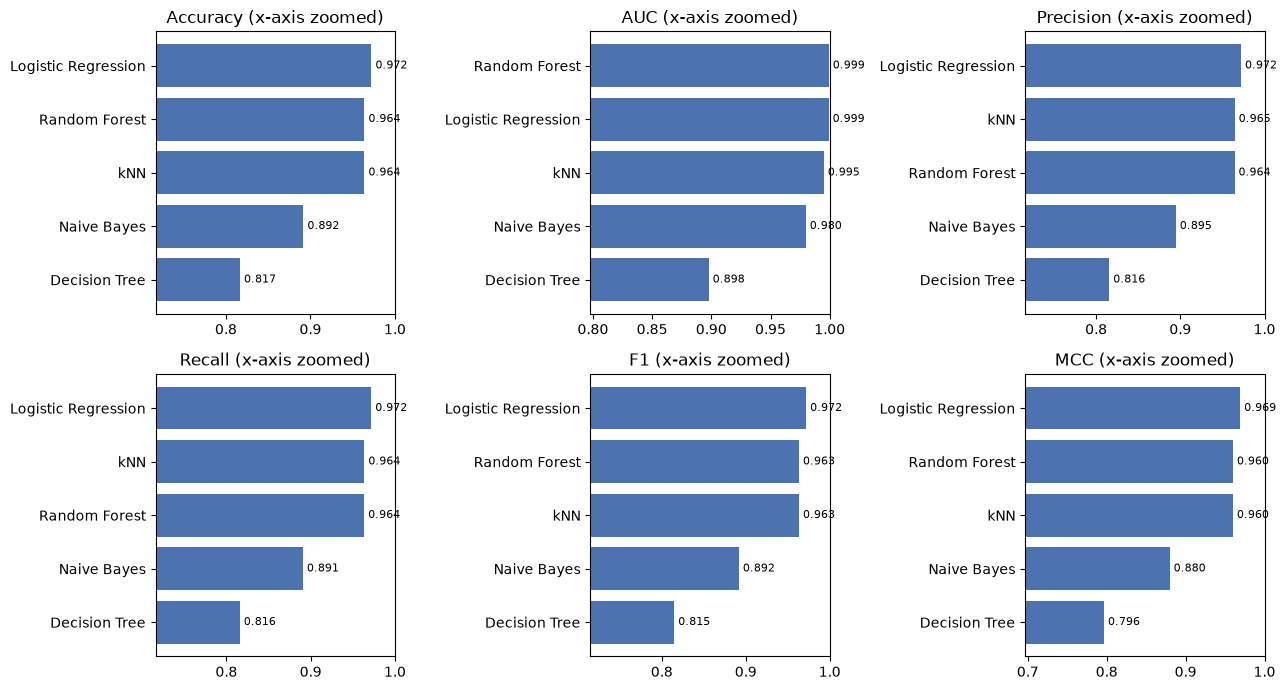

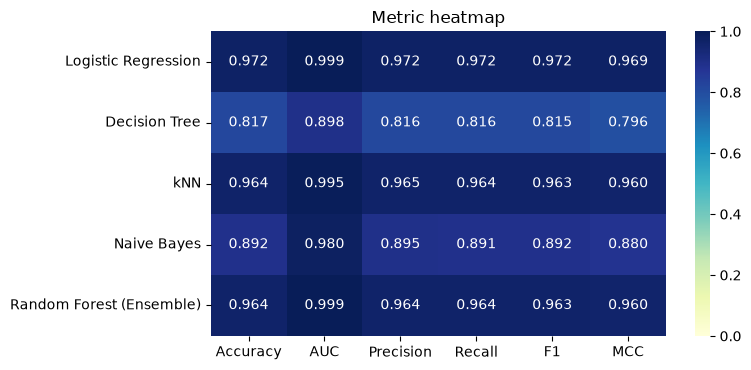

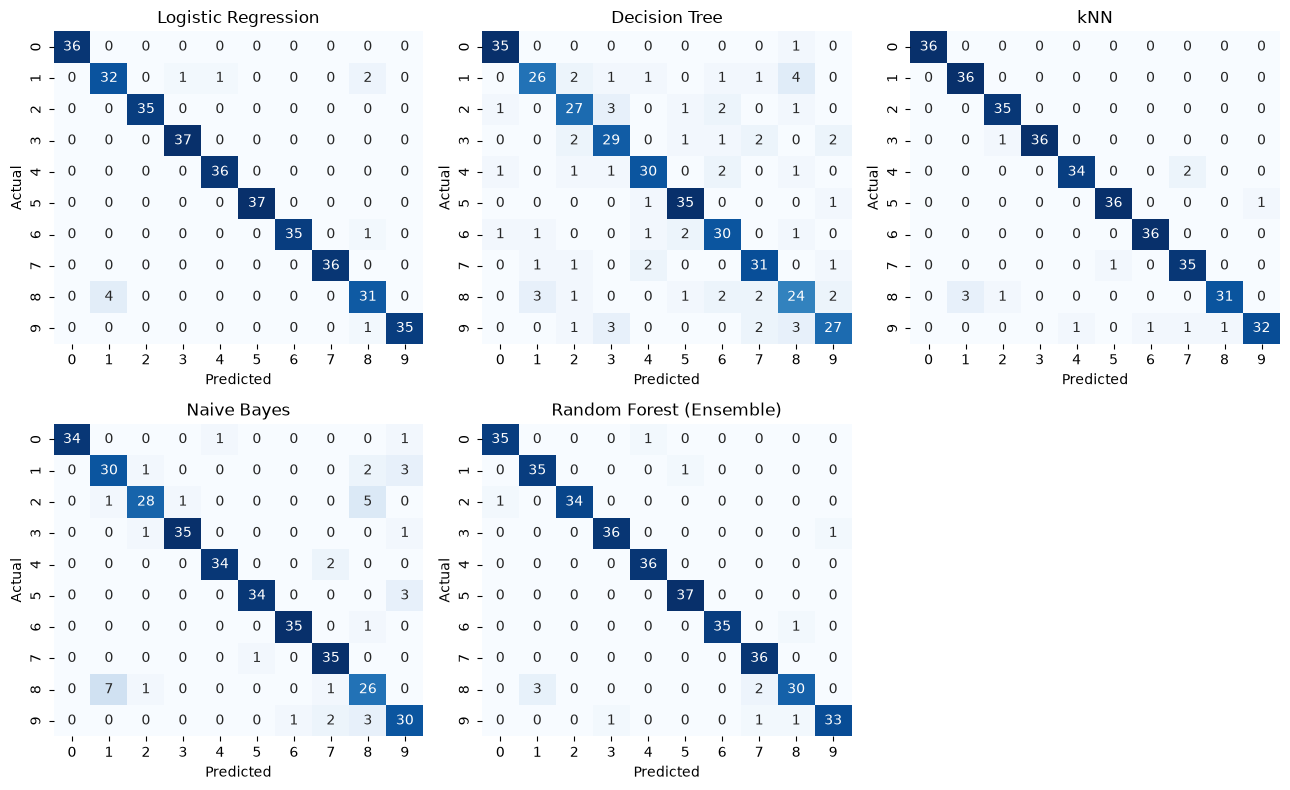

In [7]:
results.plot(kind="bar", figsize=(11, 5), width=0.8, colormap="tab10")
plt.ylim(0, 1.05); plt.xlabel(""); plt.ylabel("Score"); plt.xticks(rotation=15, ha="right")
plt.title("All evaluation metrics by model (test set)")
plt.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=8)
plt.tight_layout(); plt.savefig(IMAGE_DIR / "all_metrics_bar.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, m in zip(axes.ravel(), results.columns):
    s = results[m].sort_values()
    ax.barh(s.index.str.replace(" (Ensemble)", "", regex=False), s.values, color="#4C72B0")
    ax.set_xlim(max(0, s.min() - 0.1), 1.0); ax.set_title(m + " (x-axis zoomed)")
    for i, v in enumerate(s.values): ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(IMAGE_DIR / "per_metric_bars.png", dpi=150); plt.show()

plt.figure(figsize=(8, 3.8)); sns.heatmap(results, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Metric heatmap"); plt.ylabel(""); plt.tight_layout()
plt.savefig(IMAGE_DIR / "metric_heatmap.png", dpi=150); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, cm) in zip(axes.ravel(), cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes.ravel()[-1].axis("off"); plt.tight_layout()
plt.savefig(IMAGE_DIR / "confusion_matrices.png", dpi=150); plt.show()

## Robustness check
The test set has only 360 rows, so one extra error moves accuracy by 0.28 percentage points. The table below shows 5-fold cross-validated accuracy on all the data to see whether the ranking is stable.

In [8]:
# Robustness check: with only 360 test rows, 1 error = 0.28 pp, so also look at 5-fold CV on all data.
# (the pipelines refit imputer/scaler inside every fold, so there is no leakage)
cv_rows = []
for name, pipe in candidates.items():
    s = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    cv_rows.append({"ML Model Name": name, "CV accuracy mean": s.mean(), "CV accuracy std": s.std()})
cv_df = pd.DataFrame(cv_rows).set_index("ML Model Name").round(4)
cv_df

,CV accuracy mean,CV accuracy std
ML Model Name,,
Logistic Regression,0.9711,0.0037
Decision Tree,0.8542,0.0154
kNN,0.9789,0.0063
Naive Bayes,0.9037,0.0101
Random Forest (Ensemble),0.9800,0.0054


## Observations (seed 42)
| Model | Observation |
|---|---|
| Logistic Regression | Best on the test split: 97.2% accuracy, 10 errors, MCC 0.969, AUC 0.999. Scaled pixel features are close to linearly separable. Its most frequent mistake is true 8 predicted as 1 (4 times). Small gap between train (99.9%) and test accuracy. |
| Decision Tree | Weakest: 81.7% accuracy, 66 errors, AUC 0.898. It fits the training set perfectly (100%) but drops by ~18 points on test, i.e. it overfits; cross-validation did not find a depth limit that helps. Axis-aligned single-pixel splits suit image data poorly. |
| kNN | 96.4% accuracy, 13 errors, AUC 0.995. Same-digit images form tight clusters in pixel space. It has no real training step but prediction is the slower part (it compares against all stored training images). |
| Naive Bayes | 89.2% accuracy, 39 errors, but a high AUC (0.980): its probabilities rank classes well even though hard labels are worse. The independence assumption is violated because neighbouring pixels are strongly correlated. Cross-validation picked `var_smoothing=0.1`; it needs heavy smoothing, probably because some pixels have almost no variance. Frequent confusions: 8→1 and 2→8. |
| Random Forest | 96.4% accuracy, 13 errors, the highest AUC (0.9992) and the highest cross-validated accuracy (98.0%). Averaging many trees removes most of the single tree's variance (81.7% → 96.4%). It is the slowest model to train. |
| **Overall** | On the test split Logistic Regression is best by 3 errors (10 vs 13), but that gap is small: in 5-fold CV, Random Forest (98.0%) and kNN (97.9%) are slightly ahead of Logistic Regression (97.1%), with fold standard deviations of 0.4–0.6 points. So the top three are practically tied; Decision Tree and Naive Bayes are clearly behind. Logistic Regression is the simplest and fastest of the top group. |